# Session 2 · My fully connected baseline

I started with a model I could count by hand. I gave a dense network all 40,000 pixel values and asked it to pick one of six defects. Its validation errors gave me a concrete baseline for deciding whether convolutions helped.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
artifacts = Path("Artifacts")
manifest_path = artifacts / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)
classes = sorted(manifest.loc[manifest.split == "train", "label"].unique().tolist())
class_ids = list(range(len(classes)))
label_id = {name: i for i, name in enumerate(classes)}
assert len(classes) == 6
train_rows = manifest.loc[manifest.split == "train"].reset_index(drop=True)
val_rows = manifest.loc[manifest.split == "validation"].reset_index(drop=True)
assert train_rows.label.value_counts().reindex(classes).eq(210).all()
assert val_rows.label.value_counts().reindex(classes).eq(45).all()
assert set(train_rows.pixel_sha256).isdisjoint(val_rows.pixel_sha256)
print(f"{len(train_rows)} training images, {len(val_rows)} validation images. Running on CPU.")

1260 training images, 270 validation images. Running on CPU.


## Keeping the brightness scale consistent

I kept the crops as bytes in memory and converted each batch to floats for training. I calculated one mean and standard deviation from training pixels and reused them on validation. That way a dark crop and a bright crop still differ after normalization.

In [2]:
def load_images(rows):
    pixels = torch.empty((len(rows), 1, 200, 200), dtype=torch.uint8)
    for index, row in enumerate(rows.itertuples(index=False)):
        with Image.open(row.path) as image:
            if image.size != (200, 200) or image.mode != "L":
                raise ValueError(f"Unexpected image format: {row.path}")
            if hashlib.sha256(image.tobytes()).hexdigest() != row.pixel_sha256:
                raise ValueError(f"Pixel content changed since Session 1: {row.path}")
            pixels[index, 0] = torch.from_numpy(np.array(image))
    targets = torch.tensor(rows.label.map(label_id).tolist(), dtype=torch.long)
    return TensorDataset(pixels, targets)

train_data = load_images(train_rows)
val_data = load_images(val_rows)
# A histogram lets us compute the moments without keeping a float copy of the dataset.
hist = np.zeros(256, dtype=np.int64)
for block in train_data.tensors[0].split(32):
    hist += np.bincount(block.numpy().ravel(), minlength=256)
levels = np.arange(256) / 255.0
mean = float(np.average(levels, weights=hist))
std = float(np.sqrt(np.average((levels - mean) ** 2, weights=hist)))

def normalize(pixels):
    return (pixels.float() / 255.0 - mean) / std

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
val_loader = DataLoader(val_data, batch_size=batch_size)
print(f"Training mean {mean:.4f}, standard deviation {std:.4f} on a 0–1 scale.")

Training mean 0.5009, standard deviation 0.2125 on a 0–1 scale.


## Where the parameters go

The first dense layer connects 40,000 inputs to 64 hidden units. That alone takes 2,560,000 weights. Including biases and the six-output layer brought the total to 2,560,454. This is the number I compared with my first CNN.

In [3]:
def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(200 * 200, 64),
        nn.ReLU(),
        nn.Linear(64, len(classes)),
    )

model = make_model()
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(model)
print(f"Trainable parameters: {parameter_count:,}")
assert parameter_count == (40000 + 1) * 64 + (64 + 1) * 6

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=40000, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=6, bias=True)
)
Trainable parameters: 2,560,454


## Checking the loss on one image

I took the six raw scores from one forward pass and applied softmax so I could read the score for the true class. Its negative log matched PyTorch’s cross-entropy. In the training loop I passed the raw logits directly to the loss function.

In [4]:
loss_fn = nn.CrossEntropyLoss()
pixels, target = train_data[0]
with torch.no_grad():
    logits = model(normalize(pixels.unsqueeze(0)))
    probabilities = logits.softmax(dim=1)
    loss = loss_fn(logits, target.reshape(1))
display(pd.DataFrame({"class": classes, "logit": logits[0].tolist(),
                      "probability": probabilities[0].tolist()}).round(4))
true_probability = probabilities[0, target].item()
print(f"True class: {classes[target.item()]}. Before training, P(true class) = {true_probability:.4f}.")
print(f"Cross-entropy = -log(P(true class)) = {loss.item():.4f}")
assert math.isclose(loss.item(), -math.log(true_probability), rel_tol=1e-5)

,class,logit,probability
0,crazing,0.0027,0.1453
1,inclusion,0.1969,0.1764
2,patches,-0.0322,0.1403
3,pitted_surface,0.0391,0.1507
4,rolled_in_scale,0.2658,0.1890
5,scratches,0.3144,0.1984


True class: crazing. Before training, P(true class) = 0.1453.
Cross-entropy = -log(P(true class)) = 1.9292


## Which epoch I kept

I trained for 20 epochs with Adam and checked macro F1 after each epoch. This gave each defect class equal weight. Epoch 19 scored 0.5011. At epoch 20 it fell to 0.4252, so keeping the last weights would have given me a weaker baseline.

In [5]:
learning_rate = 0.0003
epochs = 20
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
manifest_digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
checkpoint = artifacts / "ann_baseline.pt"

@torch.inference_mode()
def validate(network):
    network.eval()
    outputs = torch.cat([network(normalize(x)) for x, _ in val_loader])
    targets = val_data.tensors[1]
    predictions = outputs.argmax(dim=1)
    score = f1_score(targets.numpy(), predictions.numpy(), labels=class_ids,
                     average="macro", zero_division=0)
    return loss_fn(outputs, targets).item(), float(score), predictions

history = []
best_score = -1.0
for epoch in range(1, epochs + 1):
    model.train()
    loss_sum = 0.0
    for pixels, targets in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(normalize(pixels)), targets)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(targets)
    val_loss, score, predictions = validate(model)
    history.append({"epoch": epoch, "train_loss": loss_sum / len(train_data),
                    "validation_loss": val_loss, "validation_macro_f1": score})
    if score > best_score:
        best_epoch, best_score = epoch, score
        best_predictions = predictions.clone()
        payload = {"state_dict": deepcopy(model.state_dict()), "classes": classes, "input_shape": [1, 200, 200],
                   "hidden_units": 64, "mean": mean, "std": std, "seed": seed,
                   "epoch": epoch, "validation_macro_f1": score, "manifest_sha256": manifest_digest}
    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:2d} | train loss {history[-1]['train_loss']:.3f} | "
              f"validation loss {val_loss:.3f} | validation macro F1 {score:.3f}")
temporary = checkpoint.with_suffix(".tmp")
torch.save(payload, temporary)
temporary.replace(checkpoint)
print(f"Selected epoch {best_epoch} with validation macro F1 {best_score:.4f}.")

Epoch  1 | train loss 2.973 | validation loss 1.703 | validation macro F1 0.359
Epoch  5 | train loss 1.133 | validation loss 1.633 | validation macro F1 0.393
Epoch 10 | train loss 0.883 | validation loss 1.777 | validation macro F1 0.421
Epoch 15 | train loss 0.618 | validation loss 1.511 | validation macro F1 0.496
Epoch 20 | train loss 0.456 | validation loss 1.762 | validation macro F1 0.425
Selected epoch 19 with validation macro F1 0.5011.


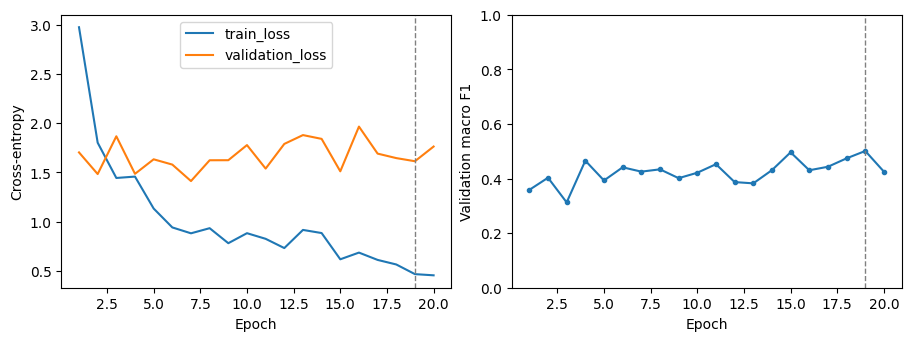

In [6]:
curves = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
curves[["train_loss", "validation_loss"]].plot(ax=axes[0], ylabel="Cross-entropy")
curves.validation_macro_f1.plot(ax=axes[1], marker=".", ylim=(0, 1), ylabel="Validation macro F1")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
plt.show()

## Where the ANN struggled

I reloaded the selected weights and reproduced all 270 validation predictions. The matrix reads from the actual class in each row to the predicted class in each column. Two mistakes tied for the largest count. The images below show one of those directions.

,precision,recall,f1-score,support
crazing,0.543,0.422,0.475,45.0
inclusion,0.516,0.356,0.421,45.0
patches,0.545,0.533,0.539,45.0
pitted_surface,0.563,0.889,0.690,45.0
rolled_in_scale,0.358,0.422,0.388,45.0
scratches,0.556,0.444,0.494,45.0


Predicted label,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
True label,,,,,,
crazing,19,0,4,14,7,1
inclusion,1,16,0,8,12,8
patches,7,0,24,3,9,2
pitted_surface,2,1,1,40,0,1
rolled_in_scale,4,2,14,2,19,4
scratches,2,12,1,4,6,20


14 of 45 crazing examples were predicted as pitted_surface.


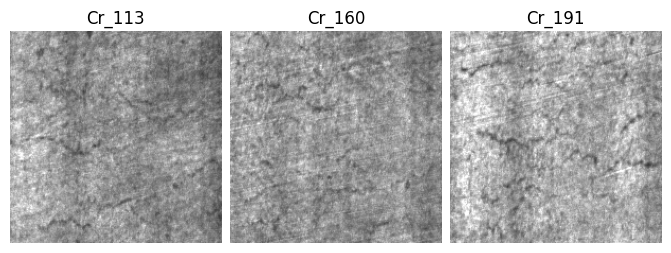

In [7]:
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
restored = make_model()
restored.load_state_dict(saved["state_dict"])
_, score, predictions = validate(restored)
assert torch.equal(best_predictions, predictions) and score == saved["validation_macro_f1"]

actual = val_data.tensors[1].numpy()
predicted = predictions.numpy()
report = classification_report(actual, predicted, labels=class_ids, target_names=classes,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.loc[classes, ["precision", "recall", "f1-score", "support"]].round(3))
matrix = confusion_matrix(actual, predicted, labels=class_ids)
display(pd.DataFrame(matrix, index=pd.Index(classes, name="True label"),
                     columns=pd.Index(classes, name="Predicted label")))
metrics = {"model": "ANN (40000 → 64 → 6)", "parameters": parameter_count, "seed": seed,
           "learning_rate": learning_rate, "batch_size": batch_size, "best_epoch": best_epoch,
           "validation_macro_f1": score, "classes": classes, "validation_report": report,
           "validation_confusion_matrix": matrix.tolist(), "history": history,
           "manifest_sha256": manifest_digest}
(artifacts / "ann_validation.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

errors = matrix.copy()
np.fill_diagonal(errors, 0)
if errors.max():
    true_id, pred_id = np.unravel_index(errors.argmax(), errors.shape)
    indices = np.flatnonzero((actual == true_id) & (predicted == pred_id))
    print(f"{len(indices)} of 45 {classes[true_id]} examples were predicted as {classes[pred_id]}.")
    count = min(3, len(indices))
    fig, axes = plt.subplots(1, count, figsize=(count * 2.2, 2.5), squeeze=False, layout="constrained")
    for ax, idx in zip(axes[0], indices[:count]):
        ax.imshow(val_data.tensors[0][idx, 0], cmap="gray", vmin=0, vmax=255)
        ax.set_title(Path(val_rows.path.iloc[idx]).stem)
        ax.axis("off")
    plt.show()

## What I took into the CNN

The ANN got 138 of 270 validation images right. It called 14 crazing images pitted surface and 14 rolled-in scale images patches. For the CNN comparison I kept the split and image resolution fixed. The change I wanted to test was whether one small filter could recognize a local pattern at different positions.